# UW-Madison GI Tract Segmentation

## Блок 0. Підготовка середовища


In [ ]:
!pip -q install -U kaggle
!pip -q install segmentation-models-pytorch albumentations scipy scikit-learn

from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Блок 1. Налаштування Kaggle API

In [ ]:
import os
import subprocess
from pathlib import Path
from google.colab import userdata
import pandas as pd

COMPETITION = "uw-madison-gi-tract-image-segmentation"
ROOT = Path("/content/data")
ROOT.mkdir(parents=True, exist_ok=True)

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
if not (ROOT / "train.csv").exists():
    subprocess.run([
        "kaggle", "competitions", "download",
        "-c", COMPETITION,
        "-p", str(ROOT),
        "--unzip"
    ], check=True)
train_df = pd.read_csv(ROOT / "train.csv")

print("CSV rows:", len(train_df))
print("PNG images:", len(list((ROOT / "train").rglob("*.png"))))
print("Dataset is ready!")

CSV rows: 115488
PNG images: 38496
Dataset is ready!


## Блок 2. Імпорти, GPU та папка результатів

In [ ]:
import gc
import random
import re
import math
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import torch
import albumentations as A
import segmentation_models_pytorch as smp

from sklearn.model_selection import GroupKFold
from torch.utils.data import Dataset, DataLoader
from pathlib import Path

assert torch.cuda.is_available(), (
    "Увімкніть GPU: Colab → Runtime → Change runtime type → GPU."
)

dev = "cuda"
CLASSES = ["large_bowel", "small_bowel", "stomach"]
IMAGE_SIZE = 256
EPOCHS = 8
BATCH_SIZE = 16
LEARNING_RATE = 3e-4
N_FOLDS = 5
SAVE_DIR = Path("/content/drive/MyDrive/gi_tract_midterm_results")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

print("GPU:", torch.cuda.get_device_name(0))
print("PyTorch:", torch.__version__)
print("Segmentation Models PyTorch:", smp.__version__)
print("Результати зберігатимуться у:", SAVE_DIR)

GPU: Tesla T4
PyTorch: 2.11.0+cu130
Segmentation Models PyTorch: 0.5.0
Результати зберігатимуться у: /content/drive/MyDrive/gi_tract_midterm_results


## Блок 3. Таблиця даних та GroupKFold за пацієнтами

In [ ]:
raw = pd.read_csv(ROOT / "train.csv")

wide = (
    raw.pivot(index="id", columns="class", values="segmentation")
       .reset_index()
)
wide.columns.name = None

wide[["case", "day", "slice"]] = (
    wide["id"].str.extract(r"case(\d+)_day(\d+)_slice_(\d+)").astype(int)
)


path_map = {}
for p in (ROOT / "train").glob("case*/case*_day*/scans/*.png"):
    case_day = p.parent.parent.name
    slice_no = p.name.split("_")[1]
    path_map[f"{case_day}_slice_{slice_no}"] = str(p)

wide["path"] = wide["id"].map(path_map)


meta = wide["path"].str.extract(
    r"slice_\d+_(\d+)_(\d+)_([\d.]+)_([\d.]+)\.png$"
)
wide["w"] = meta[0].astype(int)
wide["h"] = meta[1].astype(int)
wide["spacing_x"] = meta[2].astype(float)
wide["spacing_y"] = meta[3].astype(float)
wide = wide.sort_values(["case", "day", "slice"]).reset_index(drop=True)
wide["has_any"] = wide[CLASSES].notna().any(axis=1)

assert wide["path"].notna().all(), "Не для кожного ID знайдено PNG. Перевірте path_map."
assert len(wide) == wide["id"].nunique(), "ID зрізів мають бути унікальними."


gkf = GroupKFold(n_splits=N_FOLDS)
wide["fold"] = -1
for fold, (_, val_idx) in enumerate(gkf.split(wide, groups=wide["case"])):
    wide.loc[val_idx, "fold"] = fold

case_sets = [set(wide.loc[wide["fold"] == f, "case"]) for f in range(N_FOLDS)]
for i in range(N_FOLDS):
    for j in range(i + 1, N_FOLDS):
        assert case_sets[i].isdisjoint(case_sets[j]), "Виявлено витік case між folds."

assert (wide["fold"] >= 0).all()
assert wide["path"].notna().all()

wide.to_csv(SAVE_DIR / "folds_midterm_v2.csv", index=False)
print("Рядків / зрізів:", len(wide))
print("Пацієнтів:", wide["case"].nunique())
print("PNG paths missing:", wide["path"].isna().sum())
print("Зрізи за fold:\n", wide.groupby("fold").size())
print("Пацієнти за fold:\n", wide.groupby("fold")["case"].nunique())

Рядків / зрізів: 38496
Пацієнтів: 85
PNG paths missing: 0
Зрізи за fold:
 fold
0    7664
1    7712
2    7728
3    7712
4    7680
dtype: int64
Пацієнти за fold:
 fold
0    17
1    17
2    17
3    17
4    17
Name: case, dtype: int64


## Блок 4. RLE, сусідні зрізи та Dataset

In [ ]:
def rle_decode(rle, shape):
    """Декодує RLE у маску (height, width) у C-order."""
    height, width = shape
    flat = np.zeros(height * width, dtype=np.uint8)

    if isinstance(rle, str) and rle.strip():
        values = np.asarray(rle.split(), dtype=np.int64)

        if len(values) % 2 != 0:
            raise ValueError("Invalid RLE: expected start-length pairs")

        starts = values[0::2] - 1
        lengths = values[1::2]

        if (
            np.any(starts < 0)
            or np.any(lengths < 0)
            or np.any(starts + lengths > flat.size)
        ):
            raise ValueError("RLE values exceed mask dimensions")

        for start, length in zip(starts, lengths):
            flat[start:start + length] = 1

    return flat.reshape((height, width), order="C")


def encode_mask(mask):
    """Кодує 2D binary mask у RLE у C-order."""
    pixels = np.asarray(mask, dtype=np.uint8).ravel(order="C")
    pixels = np.concatenate(([0], pixels, [0]))

    changes = np.where(pixels[1:] != pixels[:-1])[0]
    starts = changes[::2] + 1
    lengths = changes[1::2] - changes[::2]

    return " ".join(
        str(v) for pair in zip(starts, lengths) for v in pair
    )

def add_neighbors(data):
    """Додає індекси попереднього/наступного зрізу того самого scan (case/day)."""
    data = data.sort_values(["case", "day", "slice"]).reset_index(drop=True).copy()
    groups = data.groupby(["case", "day"])
    position = groups.cumcount().to_numpy()
    group_size = groups["slice"].transform("count").to_numpy()
    idx = np.arange(len(data))
    data["i_prev"] = np.where(position > 0, idx - 1, idx)
    data["i_next"] = np.where(position < group_size - 1, idx + 1, idx)
    return data


full = add_neighbors(wide)

class GIDataset(Dataset):
    def __init__(self, full, idxs, n_slices=3, size=256, aug=None):
        self.full = full
        self.idxs = np.asarray(idxs)
        self.n_slices = n_slices
        self.size = size
        self.aug = aug

    def __len__(self):
        return len(self.idxs)

    def _load_image(self, i):
        image_path = self.full.iloc[i]["path"]
        img = cv2.imread(image_path, cv2.IMREAD_UNCHANGED)
        if img is None:
            raise FileNotFoundError(f"Не вдалося прочитати зображення: {image_path}")
        img = img.astype(np.float32)
        lo, hi = np.percentile(img, [1, 99])
        img = np.clip((img - lo) / (hi - lo + 1e-6), 0, 1)
        return cv2.resize(img, (self.size, self.size), interpolation=cv2.INTER_LINEAR)

    def __getitem__(self, k):
        i = int(self.idxs[k])
        row = self.full.iloc[i]

        if self.n_slices == 1:
            image = self._load_image(i)
            x = np.stack([image, image, image], axis=-1)
        else:
            x = np.stack([
                self._load_image(int(row["i_prev"])),
                self._load_image(i),
                self._load_image(int(row["i_next"]))
            ], axis=-1)

        original_shape = (int(row["h"]), int(row["w"]))
        mask = np.stack([
            rle_decode(row[c], original_shape) for c in CLASSES
        ], axis=-1).astype(np.float32)
        mask = cv2.resize(mask, (self.size, self.size), interpolation=cv2.INTER_NEAREST)
        if mask.ndim == 2:
            mask = mask[..., None]

        if self.aug is not None:
            transformed = self.aug(image=x, mask=mask)
            x, mask = transformed["image"], transformed["mask"]

        x = (x - 0.5) / 0.5
        x = torch.from_numpy(x.copy()).permute(2, 0, 1).float()
        mask = torch.from_numpy(np.asarray(mask, dtype=np.float32).copy()).permute(2, 0, 1).float()
        return x, mask

print("Dataset metadata готові:", full.shape)

Dataset metadata готові: (38496, 16)


## Блок 5. Перевірка даних і візуалізація масок

In [ ]:
eda = pd.DataFrame({"Орган": CLASSES,
                    "Зрізів з органом": [full[c].notna().sum() for c in CLASSES]})
eda["Частка, %"] = (eda["Зрізів з органом"] / len(full) * 100).round(1)
display(eda)
print("Зрізів без жодного органа:", round((~full["has_any"]).mean(), 3))
print(full.groupby(["w", "h"]).size())
print(full.groupby(["case", "day"]).size().value_counts())

,Орган,Зрізів з органом,"Частка, %"
0,large_bowel,14085,36.6
1,small_bowel,11201,29.1
2,stomach,8627,22.4


Зрізів без жодного органа: 0.569
w    h  
234  234      144
266  266    25920
276  276     1200
360  310    11232
dtype: int64
144    259
80      15
Name: count, dtype: int64


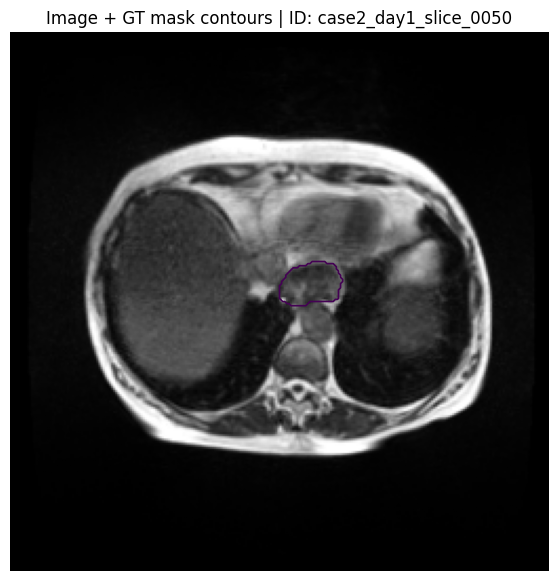

X shape: (3, 256, 256) (channels, height, width)
Y shape: (3, 256, 256) (classes, height, width)
Positive pixels by class: {'large_bowel': 0, 'small_bowel': 0, 'stomach': 485}


In [ ]:
sample_idx = int(full.index[full["has_any"]].to_numpy()[0])
sample_ds = GIDataset(full, [sample_idx], n_slices=3, size=IMAGE_SIZE)
x_sample, y_sample = sample_ds[0]

middle_image = ((x_sample[1].numpy() + 1) / 2).clip(0, 1)
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(middle_image, cmap="gray")
for c, cls in enumerate(CLASSES):
    if y_sample[c].sum() > 0:
        ax.contour(y_sample[c].numpy(), levels=[0.5], linewidths=1.2)
ax.set_title(f"Image + GT mask contours | ID: {full.loc[sample_idx, 'id']}")
ax.axis("off")
plt.show()

print("X shape:", tuple(x_sample.shape), "(channels, height, width)")
print("Y shape:", tuple(y_sample.shape), "(classes, height, width)")
print("Positive pixels by class:", {c: int(y_sample[i].sum()) for i, c in enumerate(CLASSES)})
assert tuple(x_sample.shape) == (3, IMAGE_SIZE, IMAGE_SIZE)
assert tuple(y_sample.shape) == (3, IMAGE_SIZE, IMAGE_SIZE)

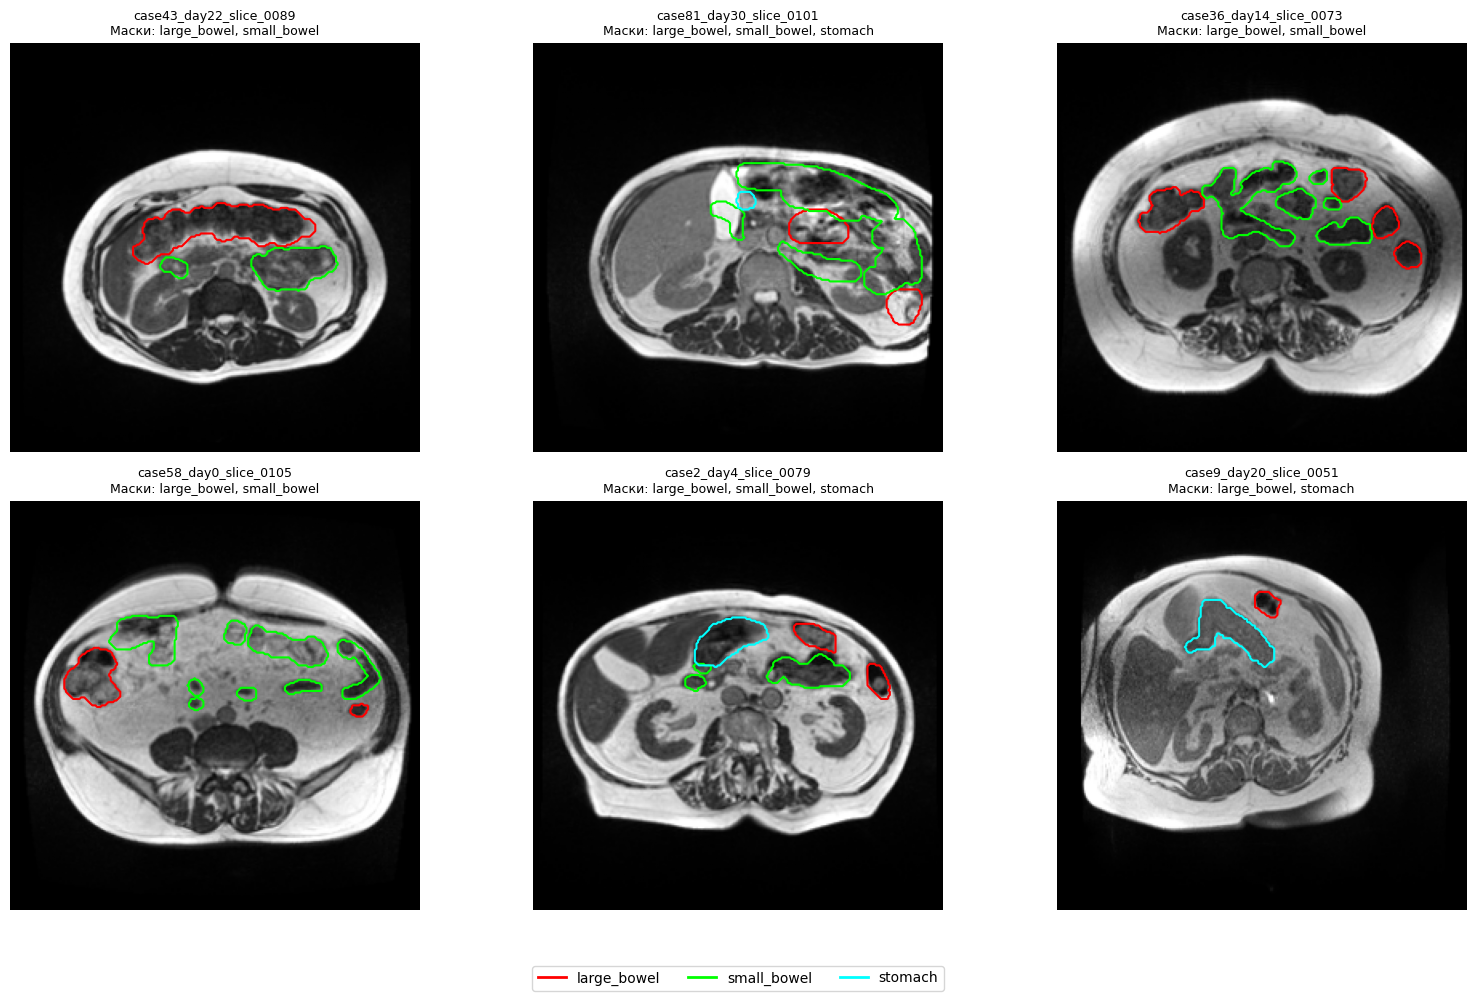

In [ ]:
rng = np.random.default_rng(42)
sample_indices = []

for cls in CLASSES:
    candidates = full.index[
        full[cls].fillna("").astype(str).str.strip().ne("")
    ].to_numpy()

    rng.shuffle(candidates)
    added = 0

    for idx in candidates:
        if int(idx) not in sample_indices:
            sample_indices.append(int(idx))
            added += 1

        if added == 2 or len(sample_indices) == 6:
            break

    if len(sample_indices) == 6:
        break

candidates = full.index[full["has_any"]].to_numpy()
rng.shuffle(candidates)

for idx in candidates:
    if int(idx) not in sample_indices:
        sample_indices.append(int(idx))

    if len(sample_indices) == 6:
        break


colors = {
    "large_bowel": "red",
    "small_bowel": "lime",
    "stomach": "cyan"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for ax, idx in zip(axes, sample_indices):
    dataset = GIDataset(
        full, [idx], n_slices=3, size=IMAGE_SIZE
    )

    x, y = dataset[0]

    image = ((x[1].numpy() + 1) / 2).clip(0, 1)
    ax.imshow(image, cmap="gray")

    visible_classes = []

    for c, cls in enumerate(CLASSES):
        mask = y[c].numpy()

        if mask.sum() > 0:
            ax.contour(
                mask,
                levels=[0.5],
                colors=[colors[cls]],
                linewidths=1.5
            )
            visible_classes.append(cls)

    ax.set_title(
        f"{full.iloc[idx]['id']}\n"
        f"Маски: {', '.join(visible_classes) if visible_classes else 'немає'}",
        fontsize=9
    )
    ax.axis("off")


from matplotlib.lines import Line2D

legend = [
    Line2D([0], [0], color=colors[cls], lw=2, label=cls)
    for cls in CLASSES
]

fig.legend(handles=legend, loc="lower center", ncol=3)
plt.tight_layout(rect=[0, 0.07, 1, 1])
plt.show()

## Блок 6. Модель, loss і метрики Dice

- **Baseline:** 2D U-Net, тобто один MRI-зріз; Dice loss.
- **Основна модель:** 2.5D U-Net, тобто три сусідні зрізи; Dice + BCE.
- Dice буде рахуватися окремо для кожного органа.

In [ ]:
def make_model(arch="Unet", encoder="resnet34"):
    model = getattr(smp, arch)(
        encoder_name=encoder,
        encoder_weights="imagenet",
        in_channels=3,
        classes=len(CLASSES)
    )
    return model.to(dev)


def make_loss(name):
    dice = smp.losses.DiceLoss(mode="multilabel")
    bce = smp.losses.SoftBCEWithLogitsLoss()
    if name == "dice":
        return dice
    if name == "bce":
        return bce
    if name == "dice+bce":
        return lambda pred, target: dice(pred, target) + bce(pred, target)
    raise ValueError(f"Невідома функція втрат: {name}")


@torch.no_grad()
def batch_dice(logits, target, threshold=0.5, eps=1e-6):
    pred = (torch.sigmoid(logits) > threshold).float()
    intersection = (pred * target).sum(dim=(2, 3))
    denominator = pred.sum(dim=(2, 3)) + target.sum(dim=(2, 3))
    dice = (2 * intersection + eps) / (denominator + eps)
    present = target.sum(dim=(2, 3)) > 0
    return dice, present


@torch.no_grad()
def evaluate_metrics(model, loader):
    model.eval()
    all_dice, all_present = [], []
    for x, y in loader:
        x = x.to(dev, non_blocking=True)
        y = y.to(dev, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(x)
        dice, present = batch_dice(logits.float(), y)
        all_dice.append(dice.cpu())
        all_present.append(present.cpu())

    D = torch.cat(all_dice, dim=0)
    P = torch.cat(all_present, dim=0)
    dice_all = D.mean(dim=0)
    dice_present = torch.stack([
        D[P[:, c], c].mean() if P[:, c].any() else torch.tensor(float("nan"))
        for c in range(len(CLASSES))
    ])
    return dice_all, dice_present, D, P


@torch.no_grad()
def predict_oof(model, loader, val_indices, full, D, P, size=IMAGE_SIZE, threshold=0.5):
    model.eval()
    pred_rles = [[] for _ in CLASSES]
    for x, _ in loader:
        x = x.to(dev, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16):
            logits = model(x)
        masks = (torch.sigmoid(logits.float()) > threshold).to(torch.uint8).cpu().numpy()
        for sample in masks:
            for c in range(len(CLASSES)):
                pred_rles[c].append(encode_mask(sample[c]))

    oof = full.loc[val_indices, ["id", "case", "day", "slice"]].copy().reset_index(drop=True)
    oof["fold"] = full.loc[val_indices, "fold"].to_numpy()
    oof["height"] = size
    oof["width"] = size
    for c, cls in enumerate(CLASSES):
        oof[f"pred_{cls}_rle"] = pred_rles[c]
        oof[f"dice_{cls}"] = D[:, c].numpy()
        oof[f"present_{cls}"] = P[:, c].numpy()
    return oof

model_test = make_model("Unet", "resnet34")
with torch.no_grad():
    logits_test = model_test(torch.randn(2, 3, IMAGE_SIZE, IMAGE_SIZE, device=dev))
print("Output shape:", tuple(logits_test.shape))
assert tuple(logits_test.shape) == (2, len(CLASSES), IMAGE_SIZE, IMAGE_SIZE)
del model_test, logits_test
torch.cuda.empty_cache()

Output shape: (2, 3, 256, 256)


## Блок 7. Функція навчання одного fold

У кожному fold найкраща за validation Dice модель зберігається на Google Drive разом із логом та OOF-передбаченнями.

In [ ]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


def run(
    full,
    fold,
    n_slices=3,
    loss="dice+bce",
    lr=LEARNING_RATE,
    epochs=EPOCHS,
    size=IMAGE_SIZE,
    bs=BATCH_SIZE,
    frac=1.0,
    tag=None,
):
    tr_idx = full.index[full["fold"] != fold].to_numpy()
    va_idx = full.index[full["fold"] == fold].to_numpy()

    if frac < 1.0:
        rng = np.random.default_rng(2026 + fold)
        tr_idx = np.sort(rng.choice(tr_idx, size=max(1, int(len(tr_idx) * frac)), replace=False))
        va_idx = va_idx[:max(1, int(len(va_idx) * frac))]

    train_ds = GIDataset(full, tr_idx, n_slices=n_slices, size=size)
    val_ds = GIDataset(full, va_idx, n_slices=n_slices, size=size)
    train_loader = DataLoader(
        train_ds, batch_size=bs, shuffle=True, num_workers=2,
        pin_memory=True, drop_last=False
    )
    val_loader = DataLoader(
        val_ds, batch_size=bs * 2, shuffle=False, num_workers=2,
        pin_memory=True, drop_last=False
    )

    model = make_model("Unet", "resnet34")
    criterion = make_loss(loss)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    scaler = torch.amp.GradScaler("cuda")

    tag = tag or f"unet_resnet34_{n_slices}slice_{loss}_fold{fold}"
    model_path = SAVE_DIR / f"model_{tag}.pt"
    log_path = SAVE_DIR / f"log_{tag}.csv"
    oof_path = SAVE_DIR / f"oof_{tag}.csv"

    best_score = -float("inf")
    history = []
    print(f"\nRun: {tag} | train={len(train_ds)} | validation={len(val_ds)}")

    for epoch in range(1, epochs + 1):
        model.train()
        total_loss, n_batches = 0.0, 0
        for x, y in train_loader:
            x = x.to(dev, non_blocking=True)
            y = y.to(dev, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type="cuda", dtype=torch.float16):
                logits = model(x)
                batch_loss = criterion(logits, y)
            scaler.scale(batch_loss).backward()
            scaler.step(optimizer)
            scaler.update()
            total_loss += float(batch_loss.item())
            n_batches += 1

        scheduler.step()
        dice_all, dice_present, D, P = evaluate_metrics(model, val_loader)
        score = torch.nanmean(dice_present).item()
        row = {
            "epoch": epoch,
            "train_loss": total_loss / max(n_batches, 1),
            "dice_all_mean": dice_all.mean().item(),
            "dice_present_mean": score,
        }
        for c, cls in enumerate(CLASSES):
            row[f"dice_present_{cls}"] = dice_present[c].item()
        history.append(row)

        print(
            f"Epoch {epoch:02d}/{epochs} | loss={row['train_loss']:.4f} "
            f"| present Dice={score:.4f}"
        )

        if np.isfinite(score) and score > best_score:
            best_score = score
            torch.save(model.state_dict(), model_path)
            oof = predict_oof(model, val_loader, va_idx, full, D, P, size=size)
            oof.to_csv(oof_path, index=False)
            print(f"  Збережено найкращу модель і OOF: {model_path.name}")

        pd.DataFrame(history).to_csv(log_path, index=False)

    del model, optimizer, scheduler, scaler
    gc.collect()
    torch.cuda.empty_cache()

    return {
        "tag": tag, "fold": fold, "loss": loss,
        "best_dice_present": best_score,
        "model_path": str(model_path), "log_path": str(log_path), "oof_path": str(oof_path)
    }


def fold_is_complete(tag, epochs):
    log_path = SAVE_DIR / f"log_{tag}.csv"
    oof_path = SAVE_DIR / f"oof_{tag}.csv"
    model_path = SAVE_DIR / f"model_{tag}.pt"
    if not (log_path.exists() and oof_path.exists() and model_path.exists()):
        return False
    try:
        log = pd.read_csv(log_path)
        return (
            "epoch" in log.columns and len(log) >= epochs
            and int(log["epoch"].max()) >= epochs
            and pd.read_csv(oof_path)["id"].is_unique
        )
    except Exception:
        return False


def train_cv(tag_prefix, n_slices, loss, epochs=EPOCHS):
    results = []
    for fold in range(N_FOLDS):
        tag = f"{tag_prefix}_f{fold}"
        if fold_is_complete(tag, epochs):
            log = pd.read_csv(SAVE_DIR / f"log_{tag}.csv")
            best = float(log["dice_present_mean"].max())
            print(f"Fold {fold}: уже завершений, best present Dice={best:.4f}")
            results.append({"tag": tag, "fold": fold, "loss": loss,
                            "best_dice_present": best, "status": "reused"})
            continue

        print(f"Fold {fold}: запускаю / повторно запускаю incomplete fold.")
        set_seed(2026 + fold)
        result = run(
            full=full, fold=fold, n_slices=n_slices, loss=loss,
            lr=LEARNING_RATE, epochs=epochs, size=IMAGE_SIZE,
            bs=BATCH_SIZE, frac=1.0, tag=tag
        )
        result["status"] = "trained"
        results.append(result)
        gc.collect()
        torch.cuda.empty_cache()

    result_df = pd.DataFrame(results)
    result_df.to_csv(SAVE_DIR / f"{tag_prefix}_summary.csv", index=False)
    return result_df

## Блок 8. Smoke test — перевірка end-to-end

Це короткий тест на 1 епосі та невеликій частині даних.

In [ ]:
RUN_SMOKE_TEST = True

if RUN_SMOKE_TEST:
    smoke_tag = "midterm_v2_smoke_test"
    smoke_result = run(
        full=full, fold=0, n_slices=3, loss="dice+bce",
        epochs=1, size=IMAGE_SIZE, bs=BATCH_SIZE, frac=0.01,
        tag=smoke_tag
    )
    smoke_oof_path = Path(smoke_result["oof_path"])
    assert smoke_oof_path.exists(), "Smoke test не створив OOF CSV."
    smoke_oof = pd.read_csv(smoke_oof_path)
    assert smoke_oof["id"].is_unique
    assert all(f"pred_{c}_rle" in smoke_oof.columns for c in CLASSES)


Run: midterm_v2_smoke_test | train=308 | validation=76
Epoch 01/1 | loss=1.6194 | present Dice=0.0556
  Збережено найкращу модель і OOF: model_midterm_v2_smoke_test.pt


## Блок 9. Експеримент 1 — 2D baseline (U-Net + Dice)

In [ ]:
baseline_results = train_cv(
    tag_prefix="midterm_v2_2d_dice",
    n_slices=1,
    loss="dice",
    epochs=EPOCHS
)
display(baseline_results)

Fold 0: запускаю / повторно запускаю incomplete fold.

Run: midterm_v2_2d_dice_f0 | train=30832 | validation=7664
Epoch 01/8 | loss=0.3864 | present Dice=0.6540
  Збережено найкращу модель і OOF: model_midterm_v2_2d_dice_f0.pt
Epoch 02/8 | loss=0.2347 | present Dice=0.6919
  Збережено найкращу модель і OOF: model_midterm_v2_2d_dice_f0.pt
Epoch 03/8 | loss=0.2049 | present Dice=0.6386
Epoch 04/8 | loss=0.1840 | present Dice=0.6841
Epoch 05/8 | loss=0.1647 | present Dice=0.6827
Epoch 06/8 | loss=0.1469 | present Dice=0.6913
Epoch 07/8 | loss=0.1333 | present Dice=0.6885
Epoch 08/8 | loss=0.1257 | present Dice=0.7094
  Збережено найкращу модель і OOF: model_midterm_v2_2d_dice_f0.pt
Fold 1: запускаю / повторно запускаю incomplete fold.

Run: midterm_v2_2d_dice_f1 | train=30784 | validation=7712
Epoch 01/8 | loss=0.3853 | present Dice=0.6543
  Збережено найкращу модель і OOF: model_midterm_v2_2d_dice_f1.pt
Epoch 02/8 | loss=0.2358 | present Dice=0.7353
  Збережено найкращу модель і OOF: mod

,tag,fold,loss,best_dice_present,model_path,log_path,oof_path,status
0,midterm_v2_2d_dice_f0,0,dice,0.709357,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,trained
1,midterm_v2_2d_dice_f1,1,dice,0.762121,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,trained
2,midterm_v2_2d_dice_f2,2,dice,0.704939,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,trained
3,midterm_v2_2d_dice_f3,3,dice,0.723949,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,trained
4,midterm_v2_2d_dice_f4,4,dice,0.738890,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,trained


## Блок 10. Експеримент 2 — 2.5D U-Net + Dice+BCE


In [ ]:
results_25d_dice_bce = train_cv(
    tag_prefix="midterm_v2_25d_dice_bce",
    n_slices=3,
    loss="dice+bce",
    epochs=EPOCHS
)
display(results_25d_dice_bce)

Fold 0: запускаю / повторно запускаю incomplete fold.

Run: midterm_v2_25d_dice_bce_f0 | train=30832 | validation=7664
Epoch 01/8 | loss=0.4421 | present Dice=0.6720
  Збережено найкращу модель і OOF: model_midterm_v2_25d_dice_bce_f0.pt
Epoch 02/8 | loss=0.2277 | present Dice=0.7013
  Збережено найкращу модель і OOF: model_midterm_v2_25d_dice_bce_f0.pt
Epoch 03/8 | loss=0.1969 | present Dice=0.7260
  Збережено найкращу модель і OOF: model_midterm_v2_25d_dice_bce_f0.pt
Epoch 04/8 | loss=0.1732 | present Dice=0.7499
  Збережено найкращу модель і OOF: model_midterm_v2_25d_dice_bce_f0.pt
Epoch 05/8 | loss=0.1552 | present Dice=0.7179
Epoch 06/8 | loss=0.1393 | present Dice=0.7309
Epoch 07/8 | loss=0.1289 | present Dice=0.7218
Epoch 08/8 | loss=0.1205 | present Dice=0.7346
Fold 1: запускаю / повторно запускаю incomplete fold.

Run: midterm_v2_25d_dice_bce_f1 | train=30784 | validation=7712
Epoch 01/8 | loss=0.4462 | present Dice=0.7401
  Збережено найкращу модель і OOF: model_midterm_v2_25d

,tag,fold,loss,best_dice_present,model_path,log_path,oof_path,status
0,midterm_v2_25d_dice_bce_f0,0,dice+bce,0.749897,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,trained
1,midterm_v2_25d_dice_bce_f1,1,dice+bce,0.777245,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,trained
2,midterm_v2_25d_dice_bce_f2,2,dice+bce,0.729940,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,trained
3,midterm_v2_25d_dice_bce_f3,3,dice+bce,0.747720,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,trained
4,midterm_v2_25d_dice_bce_f4,4,dice+bce,0.769179,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,/content/drive/MyDrive/gi_tract_midterm_result...,trained


## Блок 11. Додатковий експеримент — 2.5D U-Net + Dice

Цей експеримент допомагає відокремити вплив **сусідніх зрізів** від впливу **функції втрат**.

In [ ]:
RUN_OPTIONAL_25D_DICE_ONLY = True

if RUN_OPTIONAL_25D_DICE_ONLY:
    results_25d_dice = train_cv(
        tag_prefix="midterm_v2_25d_dice_only",
        n_slices=3,
        loss="dice",
        epochs=EPOCHS
    )
    display(results_25d_dice)

Fold 0: запускаю / повторно запускаю incomplete fold.

Run: midterm_v2_25d_dice_only_f0 | train=30832 | validation=7664
Epoch 01/8 | loss=0.3617 | present Dice=0.6135
  Збережено найкращу модель і OOF: model_midterm_v2_25d_dice_only_f0.pt
Epoch 02/8 | loss=0.2199 | present Dice=0.7110
  Збережено найкращу модель і OOF: model_midterm_v2_25d_dice_only_f0.pt
Epoch 03/8 | loss=0.1847 | present Dice=0.6856
Epoch 04/8 | loss=0.1675 | present Dice=0.7187
  Збережено найкращу модель і OOF: model_midterm_v2_25d_dice_only_f0.pt
Epoch 05/8 | loss=0.1495 | present Dice=0.7185
Epoch 06/8 | loss=0.1334 | present Dice=0.7364
  Збережено найкращу модель і OOF: model_midterm_v2_25d_dice_only_f0.pt
Epoch 07/8 | loss=0.1222 | present Dice=0.7375
  Збережено найкращу модель і OOF: model_midterm_v2_25d_dice_only_f0.pt
Epoch 08/8 | loss=0.1164 | present Dice=0.7305
Fold 1: запускаю / повторно запускаю incomplete fold.

Run: midterm_v2_25d_dice_only_f1 | train=30784 | validation=7712
Epoch 01/8 | loss=0.3647

## Блок 12. Перевірка повноти folds


In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

SAVE_DIR = Path("/content/drive/MyDrive/gi_tract_midterm_results")
EXPERIMENTS = {
    "2D baseline": "midterm_v2_2d_dice",
    "2.5D Dice+BCE": "midterm_v2_25d_dice_bce",
}

rows = []

for name, prefix in EXPERIMENTS.items():
    for fold in range(5):
        tag = f"{prefix}_f{fold}"
        log_path = SAVE_DIR / f"log_{tag}.csv"
        oof_path = SAVE_DIR / f"oof_{tag}.csv"
        model_path = SAVE_DIR / f"model_{tag}.pt"

        try:
            log = pd.read_csv(log_path)
            epochs = pd.to_numeric(log["epoch"], errors="coerce").dropna()
            oof_ok = not pd.read_csv(oof_path).empty
        except Exception:
            epochs, oof_ok = [], False

        ok = (
            model_path.is_file() and model_path.stat().st_size > 0
            and len(set(epochs)) >= 8 and max(epochs) >= 8
            and oof_ok
        )

        rows.append({
            "Модель": name,
            "Fold": fold,
            "Остання епоха": int(max(epochs)) if len(epochs) else None,
            "Статус": "OK" if ok else "INCOMPLETE"
        })

checks_df = pd.DataFrame(rows)
display(checks_df)

print(f"Завершено: {(checks_df['Статус'] == 'OK').sum()}/10 folds")

,Модель,Fold,Остання епоха,Статус
0,2D baseline,0,8,OK
1,2D baseline,1,8,OK
2,2D baseline,2,8,OK
3,2D baseline,3,8,OK
4,2D baseline,4,8,OK
5,2.5D Dice+BCE,0,8,OK
6,2.5D Dice+BCE,1,8,OK
7,2.5D Dice+BCE,2,8,OK
8,2.5D Dice+BCE,3,8,OK
9,2.5D Dice+BCE,4,8,OK


Завершено: 10/10 folds


## Блок 13. OOF-порівняння Dice за кожним органом

OOF (out-of-fold) передбачення формуються на validation-частині кожного fold, тобто кожен пацієнт оцінюється моделлю, яка не навчалася на його зрізах. Підсумкова таблиця використовує всі п'ять folds.

In [ ]:
import pandas as pd
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/gi_tract_midterm_results")
CLASSES = ["large_bowel", "small_bowel", "stomach"]

experiments = {
    "2D baseline (Dice)": "midterm_v2_2d_dice",
    "2.5D (Dice+BCE)": "midterm_v2_25d_dice_bce",
}


all_oof = {}

for name, prefix in experiments.items():
    files = [
        SAVE_DIR / f"oof_{prefix}_f{i}.csv"
        for i in range(5)
    ]

    missing = [f.name for f in files if not f.exists()]
    if missing:
        raise FileNotFoundError(f"{name}: відсутні {missing}")

    df = pd.concat([pd.read_csv(f) for f in files], ignore_index=True)

    if df["id"].duplicated().any():
        raise ValueError(f"{name}: повторюються ID")

    all_oof[name] = df
    print(f"{name}: {len(df)} OOF-записів")

if set(all_oof[experiments.keys().__iter__().__next__()]["id"]) != set(
    all_oof["2.5D (Dice+BCE)"]["id"]
):
    raise ValueError("Моделі мають різні OOF ID — порівняння зупинено.")


rows = []

for name, df in all_oof.items():
    for cls in CLASSES:
        dice = pd.to_numeric(df[f"dice_{cls}"], errors="coerce")
        present = df[f"present_{cls}"].astype(str).str.lower().isin(
            ["true", "1", "1.0"]
        )

        rows.append({
            "Модель": name,
            "Орган": cls,
            "Dice (усі зрізи)": dice.mean(),
            "Dice (орган присутній)": dice[present].mean(),
        })

comparison = pd.DataFrame(rows)

display(comparison.round(4))

comparison.to_csv(
    SAVE_DIR / "midterm_v2_dice_comparison_by_class.csv",
    index=False
)

print("Таблицю збережено.")

2D baseline (Dice): 38496 OOF-записів
2.5D (Dice+BCE): 38496 OOF-записів


,Модель,Орган,Dice (усі зрізи),Dice (орган присутній)
0,2D baseline (Dice),large_bowel,0.8778,0.7665
1,2D baseline (Dice),small_bowel,0.8531,0.6456
2,2D baseline (Dice),stomach,0.9329,0.7713
3,2.5D (Dice+BCE),large_bowel,0.8918,0.7882
4,2.5D (Dice+BCE),small_bowel,0.8675,0.6748
5,2.5D (Dice+BCE),stomach,0.9398,0.8013


Таблицю збережено.


In [ ]:
fp_rows = []
for model_name, data in all_oof.items():
    for cls in CLASSES:
        present = data[f"present_{cls}"].astype(str).str.lower().isin(["true", "1", "1.0"])
        pred_nonempty = data[f"pred_{cls}_rle"].fillna("").astype(str).str.strip().ne("")
        empty_slices = ~present
        fp_rate = pred_nonempty[empty_slices].mean()
        fp_rows.append({"Модель": model_name, "Орган": cls,
                        "FP-rate на порожніх зрізах": fp_rate})
display(pd.DataFrame(fp_rows).style.format({"FP-rate на порожніх зрізах": "{:.3f}"}))

,Модель,Орган,FP-rate на порожніх зрізах
0,2D baseline (Dice),large_bowel,0.058
1,2D baseline (Dice),small_bowel,0.062
2,2D baseline (Dice),stomach,0.020
3,2.5D (Dice+BCE),large_bowel,0.048
4,2.5D (Dice+BCE),small_bowel,0.053
5,2.5D (Dice+BCE),stomach,0.020
